# Software Effort Estimation — Desharnais Dataset

The goal is to develop regression and ANN models for software effort estimation. So the data understanding, and preprocessing steps are carried out as suitable for regression analysis.

Import libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LassoCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
np.random.seed(42)

# 1. Data Understanding

Variable descriptions (from the original dataset documentation):

* id: project id
* Project: project information
* TeamExp: team experience measured in years
* ManagerExp: manager experience measured in years
* YearEnd: year the project ended
* Length: duration of the project in months
* Effort: actual effort measured in person-hours (target variable)
* Transactions: count of basic logical transactions in the system
* Entities: number of entities in the system's data model
* PointsNonAdjust: size of the project measured in unadjusted function points
* Adjustment: function point complexity adjustment factor
* PointsAjust: size of the project measured in adjusted function points
* Language: programming language category (1, 2, 3)

In [2]:
# read the dataset file into a dataframe
effort_df = pd.read_csv("Desharnais_dataset.csv")

# check the number of rows and columns of the dataframe
effort_df.shape

(81, 13)

In [3]:
# check the head of the dataframe for a sample view
effort_df.head()

,id,Project,TeamExp,ManagerExp,YearEnd,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language
0,1,1,1,4,85,12,5152,253,52,305,34,302,1
1,2,2,0,0,86,4,5635,197,124,321,33,315,1
2,3,3,4,4,85,1,805,40,60,100,18,83,1
3,4,4,0,0,86,5,3829,200,119,319,30,303,1
4,5,5,0,0,86,4,2149,140,94,234,24,208,1


Effort is the target variable

In [4]:
# check the info of the dataframe
effort_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               81 non-null     int64
 1   Project          81 non-null     int64
 2   TeamExp          81 non-null     int64
 3   ManagerExp       81 non-null     int64
 4   YearEnd          81 non-null     int64
 5   Length           81 non-null     int64
 6   Effort           81 non-null     int64
 7   Transactions     81 non-null     int64
 8   Entities         81 non-null     int64
 9   PointsNonAdjust  81 non-null     int64
 10  Adjustment       81 non-null     int64
 11  PointsAjust      81 non-null     int64
 12  Language         81 non-null     int64
dtypes: int64(13)
memory usage: 8.4 KB


In [5]:
# check the statistics of the data
effort_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,81.0,41.000000,23.526581,1.0,21.0,41.0,61.0,81.0
Project,81.0,41.000000,23.526581,1.0,21.0,41.0,61.0,81.0
TeamExp,81.0,2.185185,1.415195,-1.0,1.0,2.0,4.0,4.0
ManagerExp,81.0,2.530864,1.643825,-1.0,1.0,3.0,4.0,7.0
YearEnd,81.0,85.740741,1.222475,82.0,85.0,86.0,87.0,88.0
Length,81.0,11.666667,7.424621,1.0,6.0,10.0,14.0,39.0
Effort,81.0,5046.308642,4418.767228,546.0,2352.0,3647.0,5922.0,23940.0
Transactions,81.0,182.123457,144.035098,9.0,88.0,140.0,224.0,886.0
Entities,81.0,122.333333,84.882124,7.0,57.0,99.0,169.0,387.0
PointsNonAdjust,81.0,304.456790,180.210159,73.0,176.0,266.0,384.0,1127.0


In [6]:
# check for duplicate rows in the df
effort_df.duplicated().sum()

0

In [7]:
# checking unique values to figure out categorical variables
effort_df.nunique()

id                 81
Project            81
TeamExp             6
ManagerExp          8
YearEnd             7
Length             26
Effort             81
Transactions       73
Entities           61
PointsNonAdjust    77
Adjustment         34
PointsAjust        77
Language            3
dtype: int64

- id and Project seem to be only identifiers only(as proved by 81 unique values). So they are of no significance to predict the effort. So drop them.
- Language looks like the categorical variable with only 3 unique values.

In [8]:
# Drop id and Project columns
effort_df = effort_df.drop(columns=["id", "Project"])
effort_df.head()

,TeamExp,ManagerExp,YearEnd,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language
0,1,4,85,12,5152,253,52,305,34,302,1
1,0,0,86,4,5635,197,124,321,33,315,1
2,4,4,85,1,805,40,60,100,18,83,1
3,0,0,86,5,3829,200,119,319,30,303,1
4,0,0,86,4,2149,140,94,234,24,208,1


Also, YearEnd in this dataset ranges from 82 to 88 (1982–1988) as seen by the statistics. Any future project you'd want to estimate would have a year value far outside anything the model has ever seen. Hence it is removed.

In [9]:
effort_df = effort_df.drop(columns=["YearEnd"])
effort_df.head()

,TeamExp,ManagerExp,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language
0,1,4,12,5152,253,52,305,34,302,1
1,0,0,4,5635,197,124,321,33,315,1
2,4,4,1,805,40,60,100,18,83,1
3,0,0,5,3829,200,119,319,30,303,1
4,0,0,4,2149,140,94,234,24,208,1


# 2. Data Visualization

Separate numerical and categorical variables. Language is the only categorical variable found.

In [10]:
num_cols = effort_df.drop(columns=["Language"])
cat_cols = effort_df[["Language"]]

## 2.1 Categorical variable

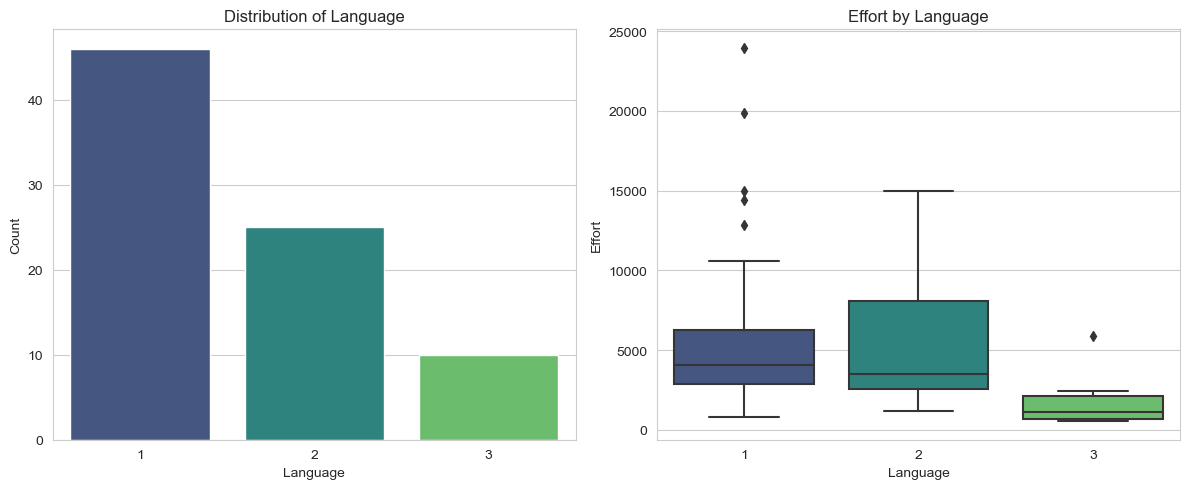

In [11]:
# Visualization of language separately and then with effort 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Countplot to understand distribution of Language
sns.countplot(x=cat_cols["Language"], palette="viridis", ax=axes[0])
axes[0].set_title("Distribution of Language")
axes[0].set_xlabel("Language")
axes[0].set_ylabel("Count")

# Plot 2: Boxplot of Effort vs Language to understand distribution of language across effort
sns.boxplot(x=effort_df["Language"], y=effort_df["Effort"], palette="viridis", ax=axes[1])
axes[1].set_title("Effort by Language")
axes[1].set_xlabel("Language")
axes[1].set_ylabel("Effort")

plt.tight_layout()
plt.show()

- Language 1 has the highest number of projects, dataset is slightly imbalanced
- Language 1 has several high outliers, potential impact on model stability
- Language 3 appears to require lower effort on average. This is just an observation and cannot be strongly concluded due to small sample size
- Language 1 and 3 have a few outliers

## 2.2 Numerical Variables

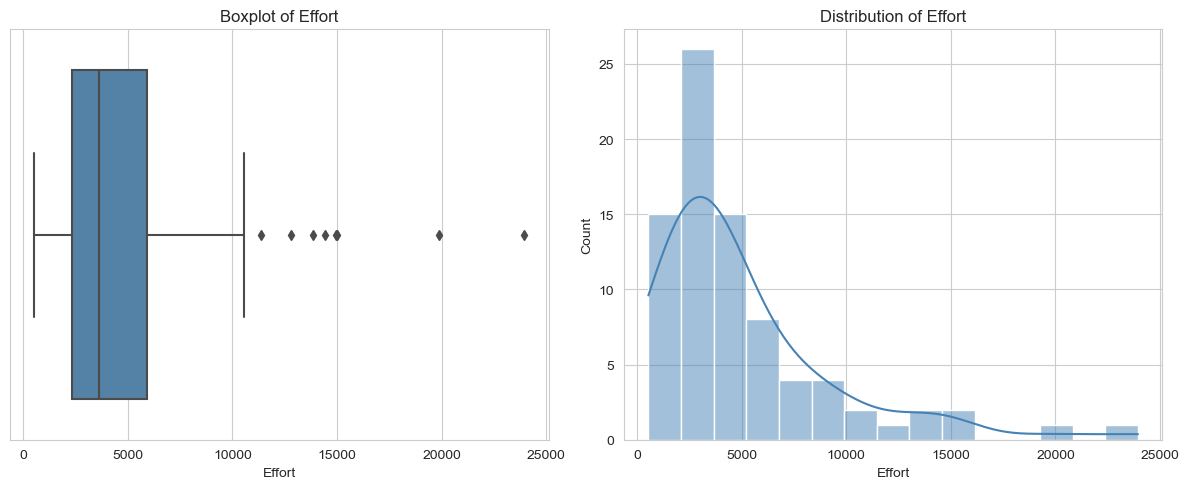

In [12]:
# Visualization of target variable with box plots to identify outliers and histogram for distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot
sns.boxplot(x=effort_df["Effort"], color="steelblue", ax=axes[0])
axes[0].set_title("Boxplot of Effort")
axes[0].set_xlabel("Effort")

# Histogram
sns.histplot(effort_df["Effort"], kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Distribution of Effort")
axes[1].set_xlabel("Effort")

plt.tight_layout()
plt.show()

* Few extreme high-value outliers are present
* Effort is highly right-skewed
* Majority of data is concentrated in the lower effort range (around 1000-6000)

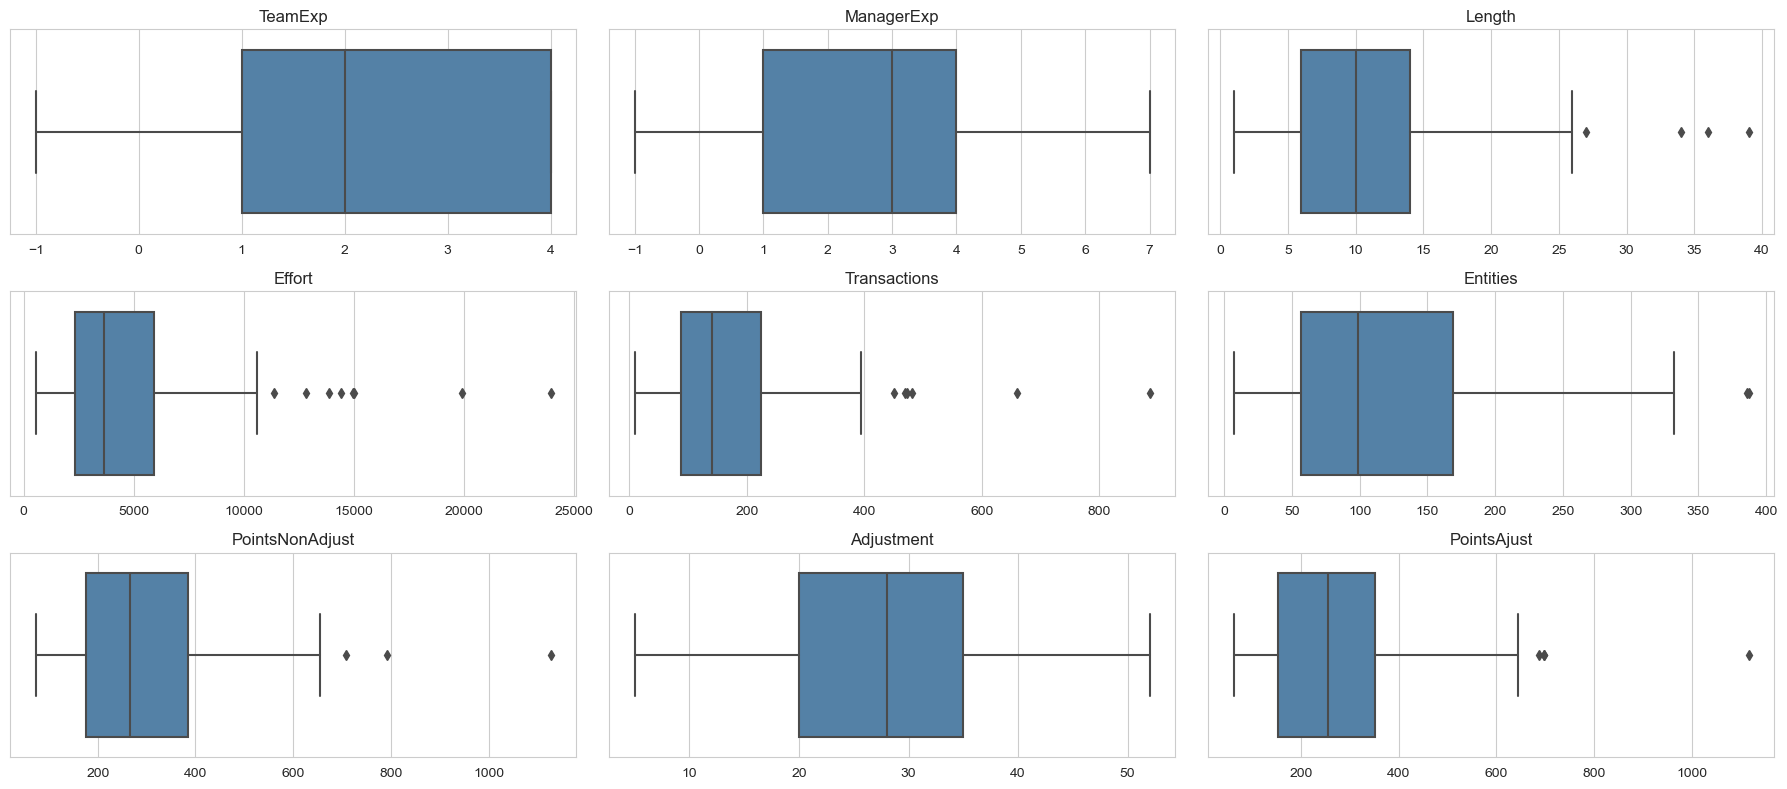

In [13]:
# Visualization of other variables to identify outliers
fig, axes = plt.subplots(3, 3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.boxplot(x=num_cols[col], ax=axes[i], color="steelblue")
    axes[i].set_title(col)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

Transactions, Entities, PointsNonAdjust and Points Adjust have a few outliers

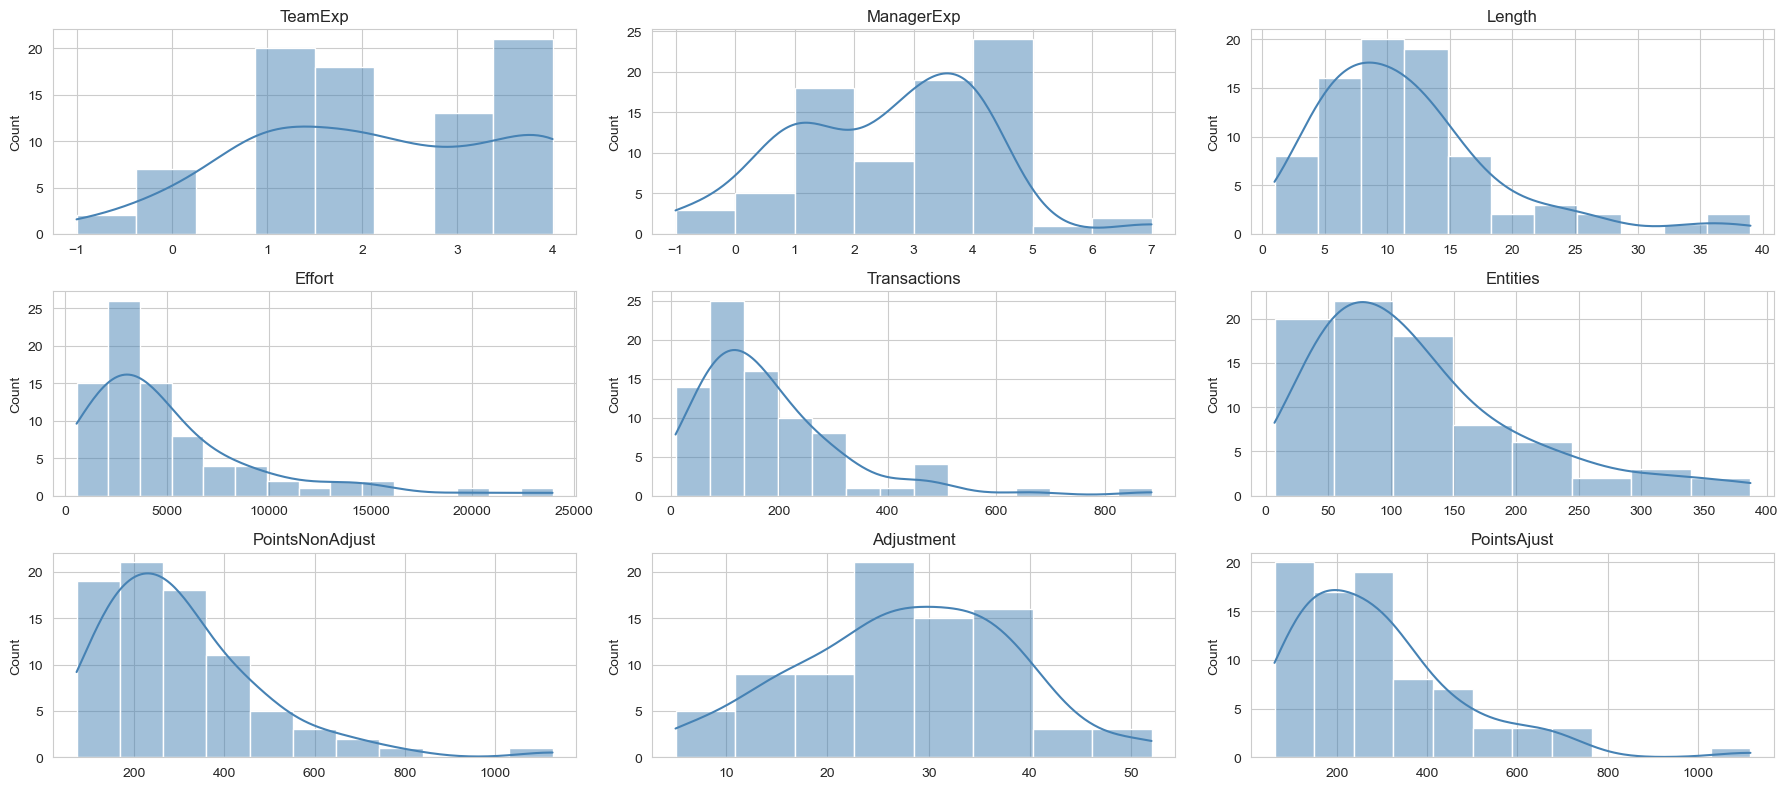

In [14]:
# Visualization of all the variables through histogram plots to understand distribution
fig, axes = plt.subplots(3, 3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.histplot(num_cols[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

* Effort, Transactions, Entities, and Function Points-related variables show strong right skew, may impact model stability
* PointsNonAdjust and PointsAjust appear similar in distribution, possible redundancy
* TeamExp and ManagerExp include negative values, which need to be handled as they are in years

Skewness and outliers in the remaining columns are not treated.
- Tree-based models are naturally robust to skew, outliers and different feature scales
- For the scale-sensitive models (Linear, Ridge, Lasso, ANN), standardization and a log-transformed target are applied inside the bootstrap loop during modeling stage

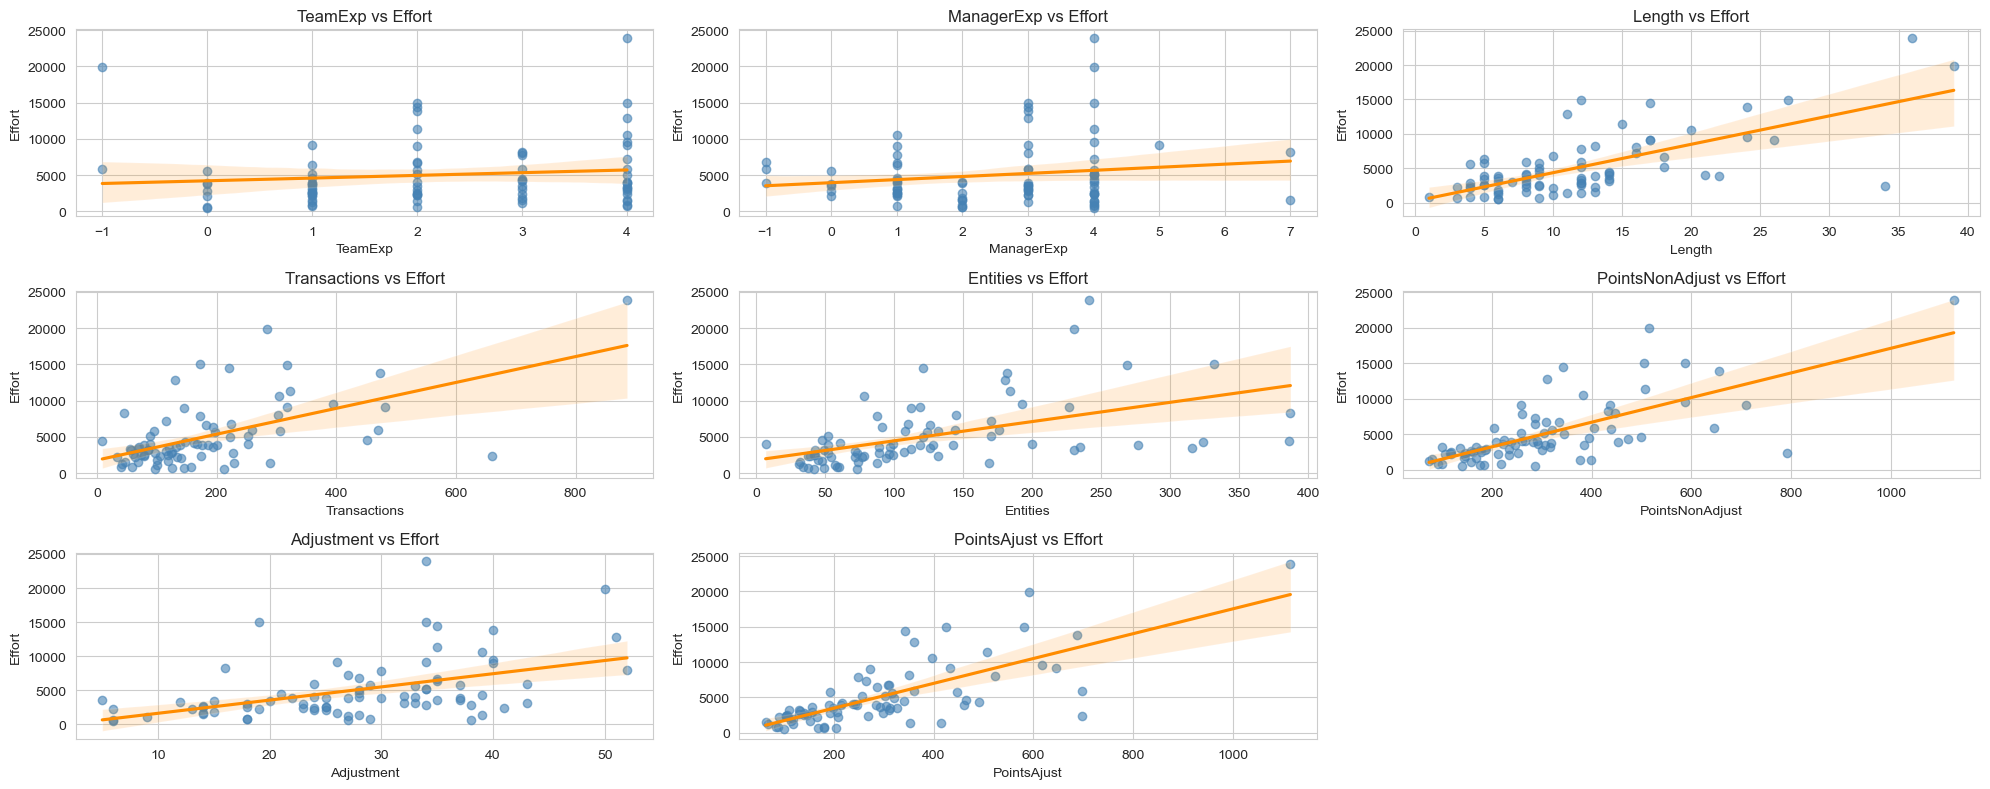

In [15]:
# Visualization of Scatter plots of each feature vs Effort with a regression trend line
features = [c for c in num_cols.columns if c != "Effort"]

fig, axes = plt.subplots(3, 3, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.regplot(
        x=effort_df[col], y=effort_df["Effort"], ax=axes[i],
        scatter_kws={"alpha": 0.6, "color": "steelblue"},
        line_kws={"color": "darkorange"}
    )
    axes[i].set_title(f"{col} vs Effort")

# hide unused axes
for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

* PointsAjust, PointsNonAdjust, Transactions, Adjustment, Length show a clear positive trend with Effort
* TeamExp and ManagerExp are discrete variables, so relationship cannot be judged based on scatterplots
* Relationships look noisy and possibly non-linear, so tree-based models are worth trying

**Length**: One concern about length is that it represents duration of effort in months. It is unsure whether this value represents the palnned duration(available at estimation time) or the actual duration only known after project completion.
If it is the actual duration, it may introduce data leakage(the model knows this during training but when actually      predicting this value will not be known).
   - As Team size is not available, it cannot be verified by comparing months/teamSize and effort * teamSize.
   - Effort and Length might be representing the same thing
   - Hence, a correlation analysis can help understand if effort and length are highly correlated or not.

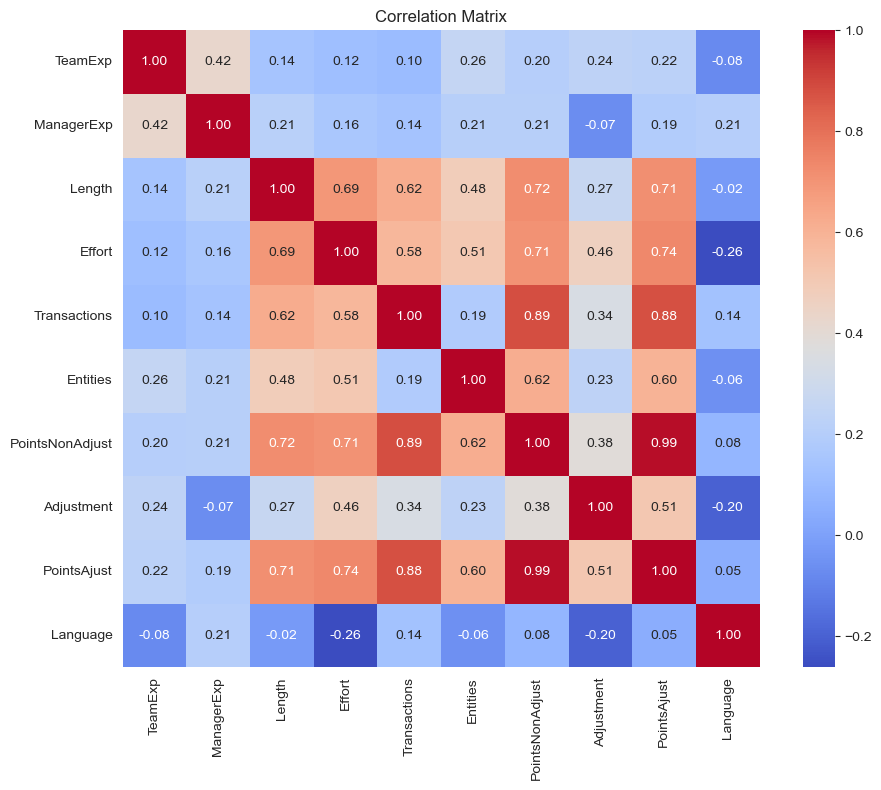

In [16]:
# Correlation matrix
corr_matrix = effort_df.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True,fmt=".2f", cmap="coolwarm",square=True)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

- The correlation between Length and Effort is approximately 0.69, suggesting a moderate relationship. However, this alone is not enough to determine whether Length introduces data leakage, especially as it is unclear when this value becomes available before or after a project. To investigate this further, each model will be trained both with and without the Length variable. If including Length leads to noticeably better performance, it may indicate that having a rough estimate of project duration is useful during planning. If the performance is similar without it, the models can still provide reliable effort estimates without relying on this variable.
- PointsAjust and PointsNonAdjust show almost perfect multicollinearity of 0.99. This could be because Adjusted Function Points are mathematically derived from Unadjusted Function Points and the Adjustment factor. One of these variables may have to be removed as they represent the same underlying project size information, and including both may introduce redundancy into the model.

# 3. Data Preprocessing

## 3.1 Handling Negative Values

TeamExp and ManagerExp contain negative values (-1), which do not make sense logically for experience variables which are calculated in years.

In [17]:
# check the affected rows with negative values
effort_df[(effort_df["TeamExp"] < 0) | (effort_df["ManagerExp"] < 0)]

,TeamExp,ManagerExp,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language
37,-1,-1,8,5922,260,144,404,24,360,1
43,-1,4,39,19894,284,230,514,50,591,1
65,2,-1,10,6783,224,110,334,28,309,2
74,0,-1,22,3941,139,143,282,22,245,2


Two interpretations were considered:
1. Negative values represent poor performance
2. Negative values represent missing data

Experience is measured in years starting from 0, so a scale below zero do not make sense logically. So the negative values are treated as **missing values**, not poor performance.

Since only 4 rows are affected and we cannot afford to delete rows from an 81 project sample dataset, median imputation is used as it is robust to skewness.

In [18]:
# replace -1 with NaN and impute with the median
effort_df["TeamExp"] = effort_df["TeamExp"].replace(-1, np.nan)
effort_df["ManagerExp"] = effort_df["ManagerExp"].replace(-1, np.nan)

effort_df["TeamExp"] = effort_df["TeamExp"].fillna(effort_df["TeamExp"].median())
effort_df["ManagerExp"] = effort_df["ManagerExp"].fillna(effort_df["ManagerExp"].median())

# verify no negative values remain
effort_df[["TeamExp", "ManagerExp"]].lt(0).sum()

TeamExp       0
ManagerExp    0
dtype: int64

## 3.2 One-Hot Encoding

Language is a categorical variable encoded as 1, 2 and 3. One-hot encoding is applied to avoid treating these values as ordinal meaning language 3 is higher than language 2 and so on just based upon their numerical value.

In [19]:
effort_df = pd.get_dummies(effort_df, columns=["Language"], drop_first=True)

# convert the boolean dummy columns to integers
effort_df["Language_2"] = effort_df["Language_2"].astype(int)
effort_df["Language_3"] = effort_df["Language_3"].astype(int)

effort_df.head()

,TeamExp,ManagerExp,Length,Effort,Transactions,Entities,PointsNonAdjust,Adjustment,PointsAjust,Language_2,Language_3
0,1.0,4.0,12,5152,253,52,305,34,302,0,0
1,0.0,0.0,4,5635,197,124,321,33,315,0,0
2,4.0,4.0,1,805,40,60,100,18,83,0,0
3,0.0,0.0,5,3829,200,119,319,30,303,0,0
4,0.0,0.0,4,2149,140,94,234,24,208,0,0


## 3.3 Multicollinearity

To avoid capturing essentially the same information multiple times, PointsNonAdjust and Adjustment are removed and only PointsAjust is retained as the project size measure. This also aligns with the fact that at planning stage of projects, they will likely only provide function points(unadjusted). But the calculation of adjustment factor might not be applicable for diverse project types. So when having to choose one of these variables, to make it more generalized and adjustedPoints is retained to keep it simpler.

In [20]:
effort_df = effort_df.drop(columns=["PointsNonAdjust", "Adjustment"])
effort_df.head()

,TeamExp,ManagerExp,Length,Effort,Transactions,Entities,PointsAjust,Language_2,Language_3
0,1.0,4.0,12,5152,253,52,302,0,0
1,0.0,0.0,4,5635,197,124,315,0,0
2,4.0,4.0,1,805,40,60,83,0,0
3,0.0,0.0,5,3829,200,119,303,0,0
4,0.0,0.0,4,2149,140,94,208,0,0


# 4. Modeling

## 4.1 Evaluation Setup - Bootstrap with Out-of-Bag testing

A single train/test split can give unstable results as it is only 81 projects. Each model is evaluated using the bootstrap re-sampling method (with 200 iterations):

1. Sample 81 projects with replacement as the training set.
2. The projects that were not drawn (Out-of-Bag samples, ~37%) are used as a test set.
3. Scaling, feature selection (SelectKBest, k=5) and the model are fitted with the training set.
4. Predictions on log(Effort) are transformed back to the original scale for calculation of metrics (models trained on log(Effort))

Metrics (all on the original Effort scale):
- RMSE and MAE - size of the errors
- R2 - variance explained

Additionally, the standard deviation of each metric for the 200 iterations helps to measure model stability and the number of features selected in each iteration indicates which features are repeatedly relevant.

All models are compared under the same conditions as the same function is used for every model. Below there is a code block for each model.

In [21]:
# Modeling pipeline built with bootstrapping, log transformation, and scaling
def bootstrap_evaluate(model, X, y, n_iterations=200, k_features=5,
                       scale=False, log_target=False, random_state=42):

    rng = np.random.RandomState(random_state)
    n_samples = len(X)

    # store the metric of every iteration
    rmse_scores = []
    mae_scores = []
    r2_scores = []

    # count how often each feature gets selected
    feature_counts = pd.Series(0, index=X.columns, dtype=int)

    # accumulate the OOB predictions of every project (for diagnostic plots)
    oob_sum = np.zeros(n_samples)
    oob_cnt = np.zeros(n_samples)

    for i in range(n_iterations):

        # Bootstrap Sampling
        train_indices = rng.choice(range(n_samples), size=n_samples, replace=True)

        # Out-of-Bag samples
        test_indices = np.array(sorted(set(range(n_samples)) - set(train_indices)))

        # Skip iteration if no OOB samples
        if len(test_indices) == 0:
            continue

        # Train/Test Split
        X_train = X.iloc[train_indices]
        y_train = y.iloc[train_indices]

        X_test = X.iloc[test_indices]
        y_test = y.iloc[test_indices]

        # Log-transform the target for scale-sensitive models
        if log_target:
            y_train_t = np.log(y_train)
        else:
            y_train_t = y_train

        # Scaling (fit on training set only)
        if scale:
            scaler = StandardScaler()
            X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
            X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

        # Feature Selection (fit on training set only)
        selector = SelectKBest(score_func=f_regression, k=min(k_features, X.shape[1]))
        X_train_fs = selector.fit_transform(X_train, y_train_t)
        X_test_fs = selector.transform(X_test)

        feature_counts[X.columns[selector.get_support()]] += 1

        # Model
        model.fit(X_train_fs, y_train_t)
        y_pred = model.predict(X_test_fs)

        # Convert back to the original scale
        if log_target:
            y_pred = np.clip(y_pred, y_train_t.min(), y_train_t.max())
            y_pred = np.exp(y_pred)

        # Evaluation
        rmse_scores.append(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_scores.append(mean_absolute_error(y_test, y_pred))
        r2_scores.append(r2_score(y_test, y_pred))

        oob_sum[test_indices] += y_pred
        oob_cnt[test_indices] += 1

    results = pd.DataFrame({
        "RMSE": rmse_scores,
        "MAE": mae_scores,
        "R2": r2_scores
    })

    oob_pred = oob_sum / np.maximum(oob_cnt, 1)

    return results, feature_counts, oob_pred


def summarize(name, results):
    print(name)
    print("-" * len(name))
    for m in results.columns:
        print(f"{m:<8}: {results[m].mean():>10.3f}  (+/- {results[m].std():.3f})")
    print()


In [22]:
# Features in dataframes with and without length
X_full = effort_df.drop(columns=["Effort"])       # with Length
X_nolen = X_full.drop(columns=["Length"])         # without Length
y = effort_df["Effort"]

print("Features (with Length)   :", list(X_full.columns))
print("Features (without Length):", list(X_nolen.columns))

Features (with Length)   : ['TeamExp', 'ManagerExp', 'Length', 'Transactions', 'Entities', 'PointsAjust', 'Language_2', 'Language_3']
Features (without Length): ['TeamExp', 'ManagerExp', 'Transactions', 'Entities', 'PointsAjust', 'Language_2', 'Language_3']


## Modeling With Length

## 1. Linear Regression

Baseline model. Simple and easy to interpret, gives a reference point for all the other models. Uses standardized features and a log-transformed target since Effort is highly right-skewed.

In [23]:
# 1. Linear Regression (with Length)

lr_model = LinearRegression()

lr_results, lr_features, lr_oob = bootstrap_evaluate(
    model=lr_model,
    X=X_full,
    y=y,
    scale=True,
    log_target=True
)

summarize("Linear Regression", lr_results)

Linear Regression
-----------------
RMSE    :   2792.831  (+/- 550.686)
MAE     :   1828.783  (+/- 373.664)
R2      :      0.508  (+/- 0.268)



## 2. Ridge Regression

Ridge regression adds regularization. Regularization shrinks the coefficients, which helps when the dataset is small and the features are correlated with each other, like here.

In [24]:
# 2. Ridge Regression (with Length)

ridge_model = Ridge(alpha=1.0)

ridge_results, ridge_features, ridge_oob = bootstrap_evaluate(
    model=ridge_model,
    X=X_full,
    y=y,
    scale=True,
    log_target=True
)

summarize("Ridge Regression", ridge_results)

Ridge Regression
----------------
RMSE    :   2740.043  (+/- 572.413)
MAE     :   1804.629  (+/- 374.589)
R2      :      0.530  (+/- 0.259)



## 3. Lasso Regression

Lasso can shrink coefficients of unimportant features all the way to zero, so it acts as an extra layer of feature selection on top of SelectKBest.

In [25]:
# 3. Lasso Regression (with Length)

lasso_model = Lasso(alpha=0.01)

lasso_results, lasso_features, lasso_oob = bootstrap_evaluate(
    model=lasso_model,
    X=X_full,
    y=y,
    scale=True,
    log_target=True
)

summarize("Lasso Regression", lasso_results)

Lasso Regression
----------------
RMSE    :   2744.208  (+/- 563.711)
MAE     :   1802.248  (+/- 366.327)
R2      :      0.530  (+/- 0.251)



## 4. Random Forest

Main non-linear model. An ensemble of decision trees, naturally robust to skewed distributions, outliers and different feature scales. So no scaling or log transformation is needed.

In [26]:
# 4. Random Forest (with Length)

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_results, rf_features, rf_oob = bootstrap_evaluate(
    model=rf_model,
    X=X_full,
    y=y,
    scale=False,
    log_target=False
)

summarize("Random Forest", rf_results)

Random Forest
-------------
RMSE    :   3509.025  (+/- 723.751)
MAE     :   2317.235  (+/- 430.313)
R2      :      0.206  (+/- 0.511)



## 5. Gradient Boosting

Builds trees one after another, each correcting the errors of the previous ones. Often more accurate than Random Forest but easier to overfit on small data, so a low learning rate and shallow trees are used.

In [27]:
# 5. Gradient Boosting (with Length)

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_results, gb_features, gb_oob = bootstrap_evaluate(
    model=gb_model,
    X=X_full,
    y=y,
    scale=False,
    log_target=False
)

summarize("Gradient Boosting", gb_results)

Gradient Boosting
-----------------
RMSE    :   3629.771  (+/- 773.274)
MAE     :   2334.191  (+/- 458.998)
R2      :      0.149  (+/- 0.530)



## 6. Artificial Neural Network (ANN)

Included to check whether a neural network improves performance on only 81 projects. To keep it simple, a small MLP with two hidden layers (32, 16) and mostly default settings is used, with early_stopping to control overfitting. Like the other scale-sensitive models, it is trained on standardized features and the log-transformed target with clipping. 

In [28]:
# 6. Artificial Neural Network (with Length)

ann_model = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    max_iter=5000,
    early_stopping=True,
    random_state=42
)

ann_results, ann_features, ann_oob = bootstrap_evaluate(
    model=ann_model,
    X=X_full,
    y=y,
    scale=True,
    log_target=True
)

summarize("ANN (MLP)", ann_results)

ANN (MLP)
---------
RMSE    :   4086.554  (+/- 1554.924)
MAE     :   2767.282  (+/- 1139.761)
R2      :     -0.270  (+/- 1.430)



# Model Comparison (with Length)

In [29]:
# summary table with the mean of each metric across the bootstrap iterations
summary = pd.DataFrame({
    "Linear Regression": lr_results.mean(),
    "Ridge": ridge_results.mean(),
    "Lasso": lasso_results.mean(),
    "Random Forest": rf_results.mean(),
    "Gradient Boosting": gb_results.mean(),
    "ANN (MLP)": ann_results.mean()
}).T

# also calculate the spread of R2 across iterations to show model stability through standard deviation
summary["R2 (sd)"] = pd.Series({
    "Linear Regression": lr_results["R2"].std(),
    "Ridge": ridge_results["R2"].std(),
    "Lasso": lasso_results["R2"].std(),
    "Random Forest": rf_results["R2"].std(),
    "Gradient Boosting": gb_results["R2"].std(),
    "ANN (MLP)": ann_results["R2"].std()
})

summary.round(3)

,RMSE,MAE,R2,R2 (sd)
Linear Regression,2792.831,1828.783,0.508,0.268
Ridge,2740.043,1804.629,0.530,0.259
Lasso,2744.208,1802.248,0.530,0.251
Random Forest,3509.025,2317.235,0.206,0.511
Gradient Boosting,3629.771,2334.191,0.149,0.530
ANN (MLP),4086.554,2767.282,-0.270,1.430


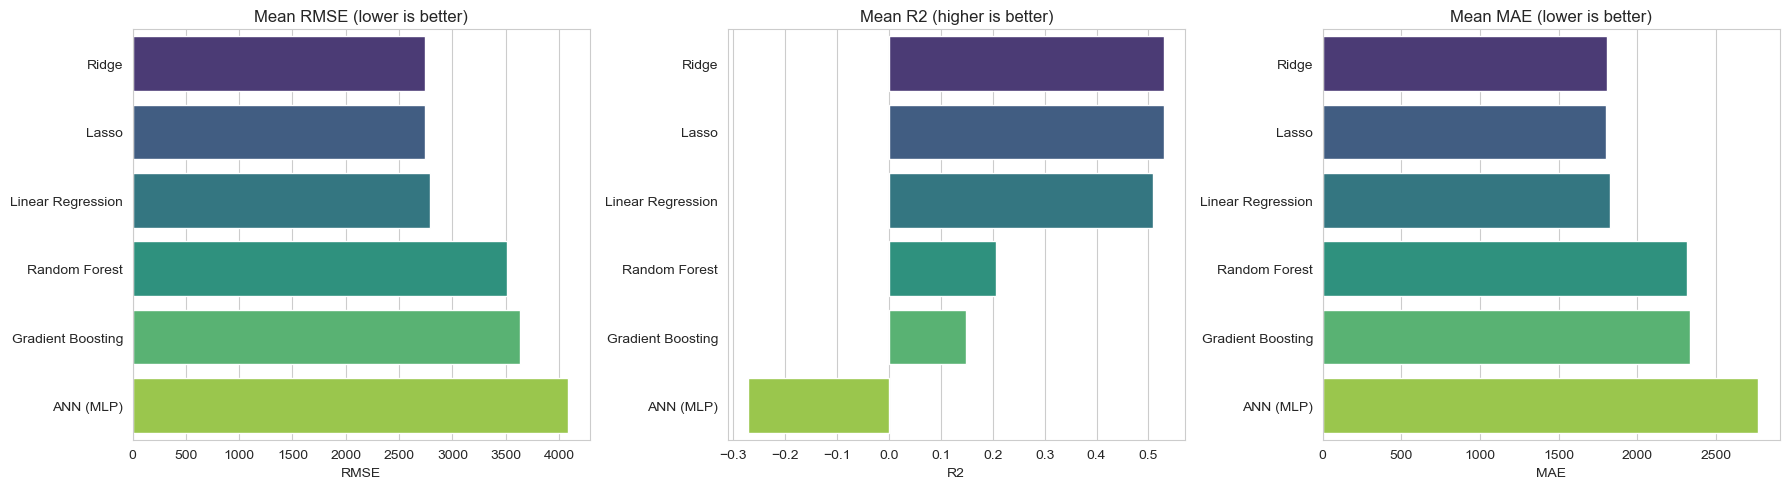

In [30]:
# Visualization for comparison of evaluation metrics
summary_sorted = summary.sort_values("RMSE")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=summary_sorted["RMSE"], y=summary_sorted.index, palette="viridis", ax=axes[0])
axes[0].set_title("Mean RMSE (lower is better)")

sns.barplot(x=summary_sorted["R2"], y=summary_sorted.index, palette="viridis", ax=axes[1])
axes[1].set_title("Mean R2 (higher is better)")

sns.barplot(x=summary_sorted["MAE"], y=summary_sorted.index, palette="viridis", ax=axes[2])
axes[2].set_title("Mean MAE (lower is better)")

plt.tight_layout()
plt.show()

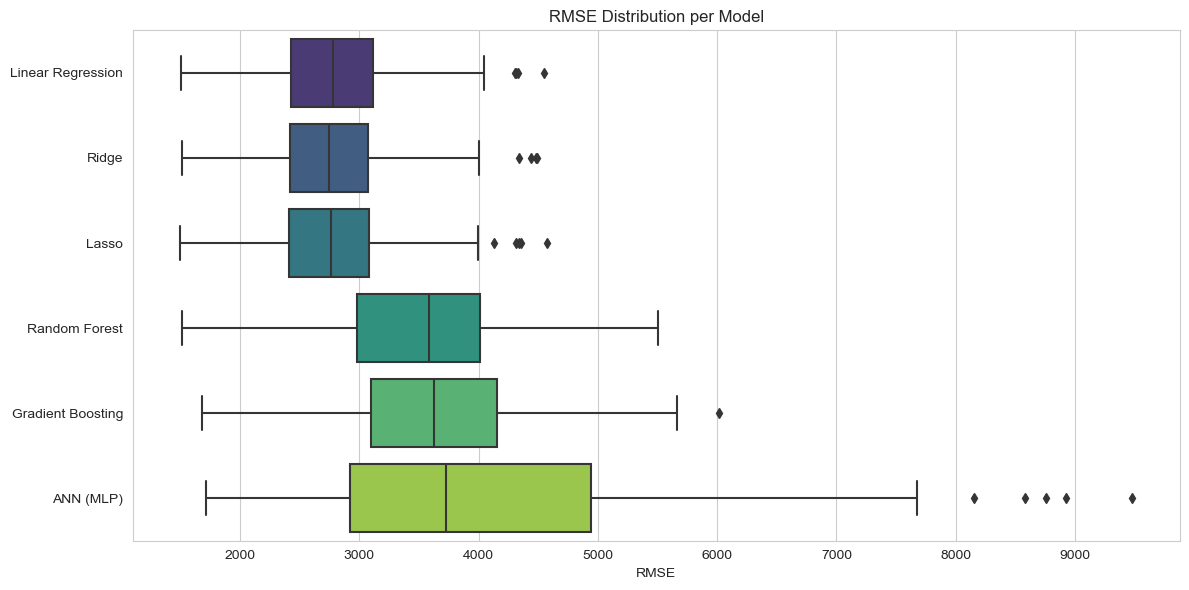

In [31]:
# RMSE distribution of each model across the bootstrap iterations
rmse_df = pd.DataFrame({
    "Linear Regression": lr_results["RMSE"],
    "Ridge": ridge_results["RMSE"],
    "Lasso": lasso_results["RMSE"],
    "Random Forest": rf_results["RMSE"],
    "Gradient Boosting": gb_results["RMSE"],
    "ANN (MLP)": ann_results["RMSE"]
})

plt.figure(figsize=(12, 6))
sns.boxplot(data=rmse_df, orient="h", palette="viridis")
plt.title("RMSE Distribution per Model")
plt.xlabel("RMSE")
plt.tight_layout()
plt.show()

From visualizations and examining the evaluation metrics:
- Ridge and Lasso give the best predictions on every metric, Linear Regression is very close behind
- Tree-based models are next. 
- The linear models also show the narrowest RMSE spread in the boxplot, so they are the most stable
- The ANN with the simple default setup performs the worst (negative R2), confirming a neural network with default settings is not suitable for a dataset of only 81 projects

## Modeling without Length (data leakage check)

The complete modeling process is repeated with Length removed. If performance drops sharply, Length was doing a large share of the predictive work, which points towards leakage. If performance barely changes, it is safe to drop it.

In [32]:
# 1. Linear Regression (without Length)

lr_model = LinearRegression()

lr_results_nl, _, _ = bootstrap_evaluate(
    model=lr_model,
    X=X_nolen,
    y=y,
    scale=True,
    log_target=True
)

summarize("Linear Regression (no Length)", lr_results_nl)

Linear Regression (no Length)
-----------------------------
RMSE    :   2843.863  (+/- 549.024)
MAE     :   1842.930  (+/- 369.637)
R2      :      0.491  (+/- 0.269)



In [33]:
# 2. Ridge Regression (without Length)

ridge_model = Ridge(alpha=1.0)

ridge_results_nl, _, _ = bootstrap_evaluate(
    model=ridge_model,
    X=X_nolen,
    y=y,
    scale=True,
    log_target=True
)

summarize("Ridge Regression (no Length)", ridge_results_nl)

Ridge Regression (no Length)
----------------------------
RMSE    :   2795.379  (+/- 556.493)
MAE     :   1810.708  (+/- 364.156)
R2      :      0.517  (+/- 0.249)



In [34]:
# 3. Lasso Regression (without Length)

lasso_model = Lasso(alpha=0.01)

lasso_results_nl, lasso_features_nl, lasso_oob_nl = bootstrap_evaluate(
    model=lasso_model,
    X=X_nolen,
    y=y,
    scale=True,
    log_target=True
)

summarize("Lasso Regression (no Length)", lasso_results_nl)

Lasso Regression (no Length)
----------------------------
RMSE    :   2779.399  (+/- 565.027)
MAE     :   1796.070  (+/- 363.986)
R2      :      0.525  (+/- 0.235)



In [35]:
# 4. Random Forest (without Length)

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_results_nl, _, _ = bootstrap_evaluate(
    model=rf_model,
    X=X_nolen,
    y=y,
    scale=False,
    log_target=False
)

summarize("Random Forest (no Length)", rf_results_nl)

Random Forest (no Length)
-------------------------
RMSE    :   3469.747  (+/- 702.899)
MAE     :   2324.954  (+/- 441.620)
R2      :      0.252  (+/- 0.414)



In [36]:
# 5. Gradient Boosting (without Length)

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_results_nl, _, _ = bootstrap_evaluate(
    model=gb_model,
    X=X_nolen,
    y=y,
    scale=False,
    log_target=False
)

summarize("Gradient Boosting (no Length)", gb_results_nl)

Gradient Boosting (no Length)
-----------------------------
RMSE    :   3574.446  (+/- 789.628)
MAE     :   2346.596  (+/- 486.966)
R2      :      0.194  (+/- 0.483)



In [37]:
# 6. Artificial Neural Network (without Length)

ann_model = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    max_iter=5000,
    early_stopping=True,
    random_state=42
)

ann_results_nl, _, _ = bootstrap_evaluate(
    model=ann_model,
    X=X_nolen,
    y=y,
    scale=True,
    log_target=True
)

summarize("ANN (no Length)", ann_results_nl)

ANN (no Length)
---------------
RMSE    :   4163.947  (+/- 1536.231)
MAE     :   2785.026  (+/- 1164.059)
R2      :     -0.304  (+/- 1.489)



In [38]:
# summary table without Length
summary_nl = pd.DataFrame({
    "Linear Regression": lr_results_nl.mean(),
    "Ridge": ridge_results_nl.mean(),
    "Lasso": lasso_results_nl.mean(),
    "Random Forest": rf_results_nl.mean(),
    "Gradient Boosting": gb_results_nl.mean(),
    "ANN (MLP)": ann_results_nl.mean()
}).T

# also record the spread of R2 across iterations to show model stability
summary_nl["R2 (sd)"] = pd.Series({
    "Linear Regression": lr_results_nl["R2"].std(),
    "Ridge": ridge_results_nl["R2"].std(),
    "Lasso": lasso_results_nl["R2"].std(),
    "Random Forest": rf_results_nl["R2"].std(),
    "Gradient Boosting": gb_results_nl["R2"].std(),
    "ANN (MLP)": ann_results_nl["R2"].std()
})

summary_nl.round(3)

,RMSE,MAE,R2,R2 (sd)
Linear Regression,2843.863,1842.930,0.491,0.269
Ridge,2795.379,1810.708,0.517,0.249
Lasso,2779.399,1796.070,0.525,0.235
Random Forest,3469.747,2324.954,0.252,0.414
Gradient Boosting,3574.446,2346.596,0.194,0.483
ANN (MLP),4163.947,2785.026,-0.304,1.489


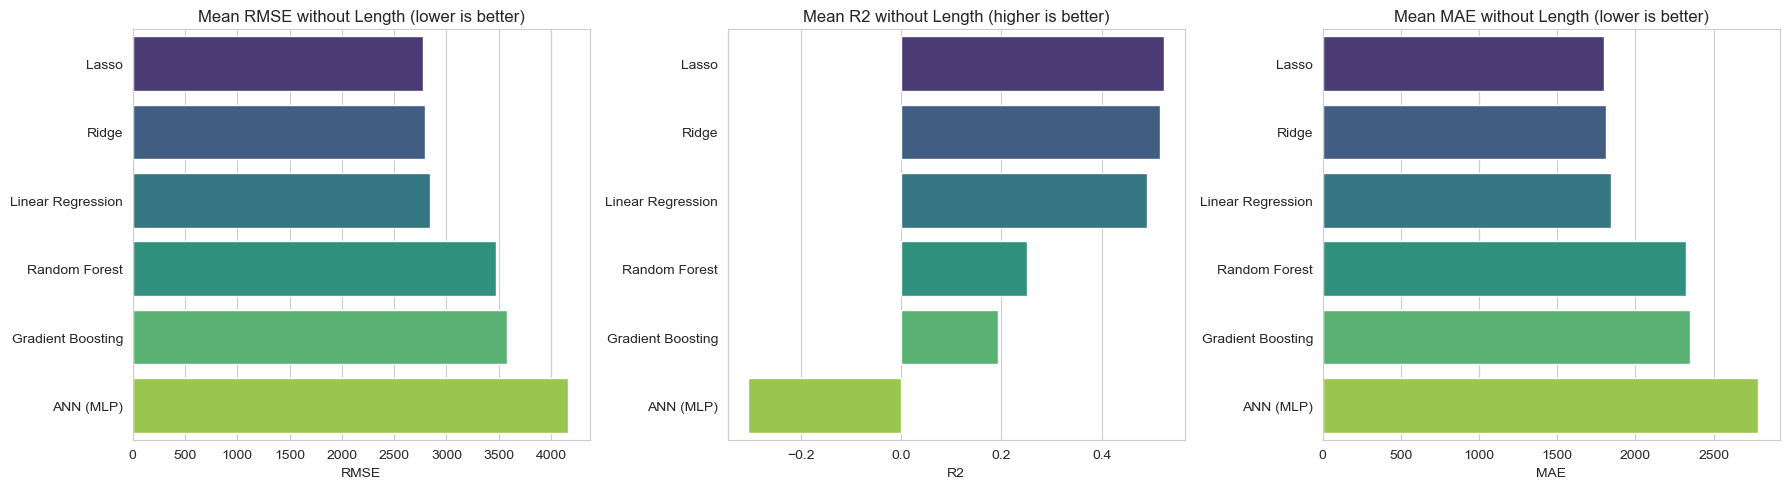

In [39]:
# Visualization for comparison of evaluation metrics
summary_nl_sorted = summary_nl.sort_values("RMSE")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=summary_nl_sorted["RMSE"], y=summary_nl_sorted.index, palette="viridis", ax=axes[0])
axes[0].set_title("Mean RMSE without Length (lower is better)")

sns.barplot(x=summary_nl_sorted["R2"], y=summary_nl_sorted.index, palette="viridis", ax=axes[1])
axes[1].set_title("Mean R2 without Length (higher is better)")

sns.barplot(x=summary_nl_sorted["MAE"], y=summary_nl_sorted.index, palette="viridis", ax=axes[2])
axes[2].set_title("Mean MAE without Length (lower is better)")

plt.tight_layout()
plt.show()

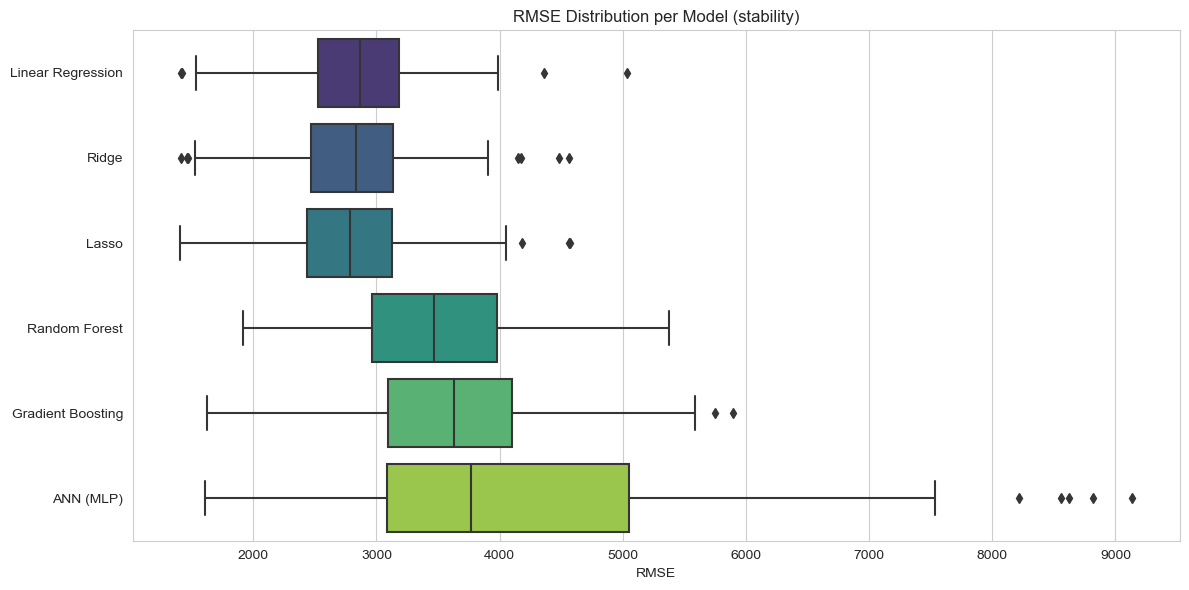

In [40]:
# RMSE distribution of each model 
rmse_nl_df = pd.DataFrame({
    "Linear Regression": lr_results_nl["RMSE"],
    "Ridge": ridge_results_nl["RMSE"],
    "Lasso": lasso_results_nl["RMSE"],
    "Random Forest": rf_results_nl["RMSE"],
    "Gradient Boosting": gb_results_nl["RMSE"],
    "ANN (MLP)": ann_results_nl["RMSE"]
})

plt.figure(figsize=(12, 6))
sns.boxplot(data=rmse_nl_df, orient="h", palette="viridis")
plt.title("RMSE Distribution per Model (stability)")
plt.xlabel("RMSE")
plt.tight_layout()
plt.show()

In [41]:
# side-by-side comparison of R2, RMSE and MAE, with vs without Length
comparison_full = pd.concat(
    {
        "With Length": summary[["R2", "R2 (sd)", "RMSE", "MAE"]],
        "Without Length": summary_nl[["R2", "R2 (sd)", "RMSE", "MAE"]]
    },
    axis=1
)
comparison_full = comparison_full.loc[summary.sort_values("RMSE").index]
comparison_full.round(3)


With Length                             Without Length  \
                           R2 R2 (sd)      RMSE       MAE             R2   
Ridge                   0.530   0.259  2740.043  1804.629          0.517   
Lasso                   0.530   0.251  2744.208  1802.248          0.525   
Linear Regression       0.508   0.268  2792.831  1828.783          0.491   
Random Forest           0.206   0.511  3509.025  2317.235          0.252   
Gradient Boosting       0.149   0.530  3629.771  2334.191          0.194   
ANN (MLP)              -0.270   1.430  4086.554  2767.282         -0.304   

                                               
                  R2 (sd)      RMSE       MAE  
Ridge               0.249  2795.379  1810.708  
Lasso               0.235  2779.399  1796.070  
Linear Regression   0.269  2843.863  1842.930  
Random Forest       0.414  3469.747  2324.954  
Gradient Boosting   0.483  3574.446  2346.596  
ANN (MLP)           1.489  4163.947  2785.026

In [42]:
# percentage change of RMSE when Length is removed
pct_change = pd.DataFrame({
    "RMSE change (%)": (summary_nl["RMSE"] - summary["RMSE"]) / summary["RMSE"] * 100
})
pct_change.round(1)


,RMSE change (%)
Linear Regression,1.8
Ridge,2.0
Lasso,1.3
Random Forest,-1.1
Gradient Boosting,-1.5
ANN (MLP),1.9


- Looking at all difference, removing Length changes each of them only marginally, around 0 to 2% for the models. So removing length will not affect the model performane significantly
- Since the planned vs actual duration question cannot be resolved from this dataset, the safe recommendation is to use the **without Length** models. This removes any leakage risk at almost no cost in accuracy
- Within the without Length models, Lasso is consistently at the top on all three metrics
- **Decision: Lasso, without Length, is the final model** carried forward to feature importance, diagnostics and tuning


## Feature Importance of the Best Model

Linear models do not have feature importances like tree models. Instead, the absolute values of the coefficients on standardized features are used. Since all features are on the same scale after standardization, a larger absolute coefficient means a larger influence on the predicted effort.

Feature selection frequency across bootstrap iterations (%):
Transactions    100.0
Entities        100.0
PointsAjust     100.0
Language_3       99.5
TeamExp          74.0
ManagerExp       17.0
Language_2        9.5
dtype: float64


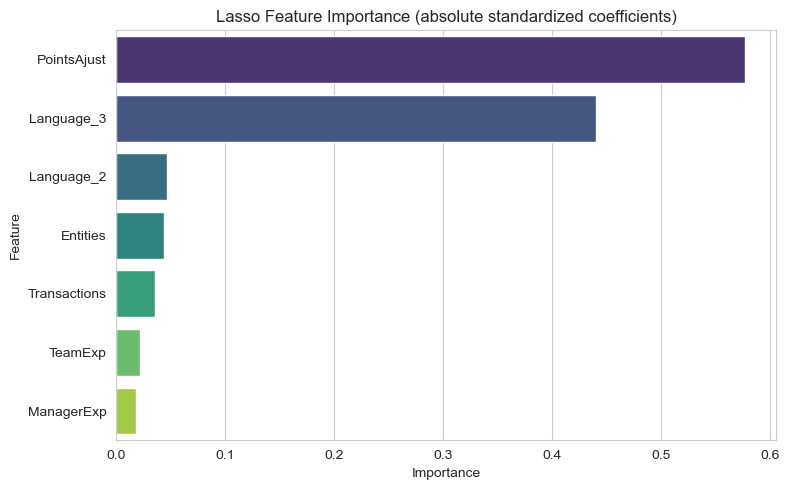

,Feature,Importance
4,PointsAjust,0.576834
6,Language_3,0.440430
5,Language_2,0.046103
3,Entities,0.043790
2,Transactions,0.035851
0,TeamExp,0.021983
1,ManagerExp,0.018400


In [43]:
# Lasso Feature Importance (without Length)

# selection frequency of each feature, reused from the stored bootstrap results
selection_pct = lasso_features_nl / 200 * 100
print("Feature selection frequency across bootstrap iterations (%):")
print(selection_pct.sort_values(ascending=False).round(1))

# fit the configuration once agaiin on the full dataset to calculate feature selection frequency
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_nolen), columns=X_nolen.columns)
y_log = np.log(y)

lasso_final = Lasso(alpha=0.01)
lasso_final.fit(X_scaled, y_log)

importance_df = pd.DataFrame({
    "Feature": X_nolen.columns,
    "Importance": np.abs(lasso_final.coef_)
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance", y="Feature", palette="viridis")
plt.title("Lasso Feature Importance (absolute standardized coefficients)")
plt.tight_layout()
plt.show()

importance_df

- PointsAjust clearly is the most influential feature
- Language_3 comes second, projects in Language 3 need noticeably lower effort for the same size
- Transactions, Entities and PointsAjust were selected in 100% of the bootstrap iterations and Language_3 in 99.5%, so these are consistently informative and not selected by chance
- Interesting point: Transactions and Entities are always selected but end up with small coefficients in the final model. This may be because PointsAjust already carries most of the shared size information, so Lasso shrinks the overlapping features, which is exactly its job
- Experience variables contribute comparatively less

# Best Model Diagnostics

Each project's Out-of-Bag predictions were already stored during the bootstrap run, so they are reused here directly with no refitting.

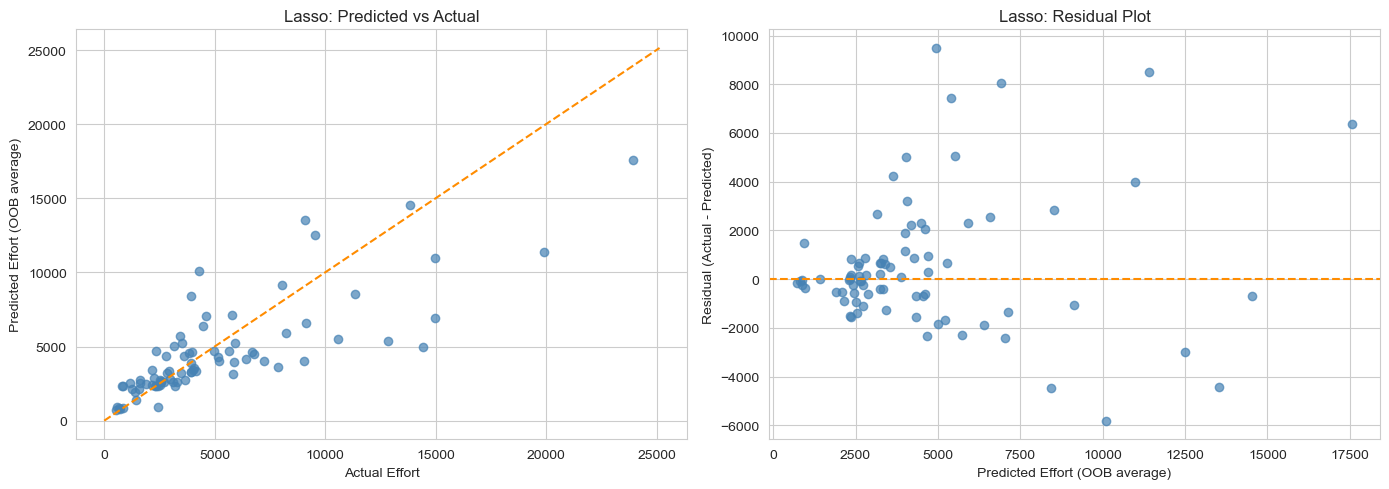

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs Actual
axes[0].scatter(y, lasso_oob_nl, alpha=0.7, color="steelblue")
lims = [0, max(y.max(), lasso_oob_nl.max()) * 1.05]
axes[0].plot(lims, lims, "--", color="darkorange")
axes[0].set_xlabel("Actual Effort")
axes[0].set_ylabel("Predicted Effort (OOB average)")
axes[0].set_title("Lasso: Predicted vs Actual")

# Residuals
residuals = y - lasso_oob_nl
axes[1].scatter(lasso_oob_nl, residuals, alpha=0.7, color="steelblue")
axes[1].axhline(0, linestyle="--", color="darkorange")
axes[1].set_xlabel("Predicted Effort (OOB average)")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Lasso: Residual Plot")

plt.tight_layout()
plt.show()

# Hyperparameter Tuning and Model Improvement Experiments

The selected Lasso model (alpha=0.01, SelectKBest k=5) explains around 53% of the variance in effort. Before finalising it, hyper



To keep the comparison fair and leak-free, the baseline and the tuned versions are wrapped in a scikit-learn `Pipeline` and evaluated with the same bootstrap and out-of-bag procedure used before. All tuning (alpha selection) happens by cross-validation inside each bootstrap training fold, so no information leaks from the out-of-bag test set. Both use the final feature set (without `Length`).


In [45]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import Pipeline

## A pipeline-based bootstrap evaluator

The main `bootstrap_evaluate` function feeds a fixed feature array to the model, which cannot support pipeline-internal cross-validation. This helper reuses the identical bootstrap sampling, out-of-bag testing, log-target and clipping logic, but accepts a full `Pipeline` so LassoCV can tune alpha internally on the training fold only, keeping the out-of-bag test set leak-free.


In [46]:
# modeling pipeline as before
def bootstrap_pipeline(make_pipeline, X, y, n_iterations=200, random_state=42):

    rng = np.random.RandomState(random_state)
    n_samples = len(X)

    rmse_scores = []
    mae_scores = []
    r2_scores = []

    for i in range(n_iterations):

        train_indices = rng.choice(range(n_samples), size=n_samples, replace=True)
        test_indices = np.array(sorted(set(range(n_samples)) - set(train_indices)))
        if len(test_indices) == 0:
            continue

        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]

        # log-transform target (same as the scale-sensitive main models)
        y_train_t = np.log(y_train)

        # fit the whole pipeline on the training fold only
        pipeline = make_pipeline()
        pipeline.fit(X_train, y_train_t)
        y_pred = pipeline.predict(X_test)

        # back-transform, clipping to the training range first
        y_pred = np.clip(y_pred, y_train_t.min(), y_train_t.max())
        y_pred = np.exp(y_pred)

        rmse_scores.append(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_scores.append(mean_absolute_error(y_test, y_pred))
        r2_scores.append(r2_score(y_test, y_pred))

    return pd.DataFrame({
        "RMSE": rmse_scores,
        "MAE": mae_scores,
        "R2": r2_scores
    })


In [47]:
# tuning results are stored in a collection for comparison
tuning_results = {}

## Baseline (current selected Lasso)

The current model rebuilt as a pipeline, so it is compared to the tuning strategies on exactly equal footing.

In [48]:
# Baseline: StandardScaler -> SelectKBest(k=5) -> Lasso(alpha=0.01)

def make_baseline():
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_regression, k=5)),
        ("lasso", Lasso(alpha=0.01, max_iter=5000))
    ])

tuning_results["Baseline Lasso"] = bootstrap_pipeline(make_baseline, X_nolen, y)
summarize("Baseline Lasso", tuning_results["Baseline Lasso"])

Baseline Lasso
--------------
RMSE    :   2779.399  (+/- 565.027)
MAE     :   1796.070  (+/- 363.986)
R2      :      0.525  (+/- 0.235)



Baseline lasso is experimented with alpha=0.001

In [49]:
def make_baseline():
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_regression, k=5)),
        ("lasso", Lasso(alpha=0.001, max_iter=5000))
    ])

tuning_results["Baseline Lasso with alpha=0.001"] = bootstrap_pipeline(make_baseline, X_nolen, y)
summarize("Baseline Lasso with alpha=0.001", tuning_results["Baseline Lasso with alpha=0.001"])

Baseline Lasso with alpha=0.001
-------------------------------
RMSE    :   2829.562  (+/- 542.203)
MAE     :   1834.927  (+/- 364.623)
R2      :      0.498  (+/- 0.259)



This model with alpha=0.001 did not perform better than the baseline Lasso model when RMSE, MAE and R2 are compared.

## LassoCV without SelectKBest

Instead of a fixed `alpha=0.01` with a SelectKBest cap of 5 features, LassoCV selects alpha automatically by 5-fold cross-validation on each training fold, and the SelectKBest step is removed entirely so Lasso's own L1 penalty performs the feature selection on all available features.


In [51]:
# LassoCV (all features, no SelectKBest cap)

alpha_grid = np.logspace(-3, 1, 25)

def make_lassocv():
    return Pipeline([
        ("scale", StandardScaler()),
        ("lasso", LassoCV(alphas=alpha_grid, cv=3, max_iter=5000))
    ])

tuning_results["LassoCV (no SelectKBest)"] = bootstrap_pipeline(make_lassocv, X_nolen, y)
summarize("LassoCV (no SelectKBest)", tuning_results["LassoCV (no SelectKBest)"])


LassoCV (no SelectKBest)
------------------------
RMSE    :   2839.416  (+/- 564.399)
MAE     :   1831.024  (+/- 372.817)
R2      :      0.505  (+/- 0.204)



## Comparison of tuning strategies

In [52]:
# summary table: mean and std of R2, RMSE and MAE for each strategy
tuning_summary = pd.DataFrame({
    name: {
        "R2 mean": res["R2"].mean(),
        "R2 std": res["R2"].std(),
        "RMSE": res["RMSE"].mean(),
        "MAE mean": res["MAE"].mean(),
    }
    for name, res in tuning_results.items()
}).T

tuning_summary.round(3)

,R2 mean,R2 std,RMSE,MAE mean
Baseline Lasso,0.525,0.235,2779.399,1796.070
Baseline Lasso with alpha=0.001,0.498,0.259,2829.562,1834.927
LassoCV (no SelectKBest),0.505,0.204,2839.416,1831.024


## Findings from the tuning experiments

Lasso with alpha=0.001 did not improve in any metrics.
LassoCV without SelectKBest did not improve on the baseline Lasso:

- Mean R2 is slightly lower than the baseline (about 0.51 vs 0.53), and RMSE/MAE are marginally higher (RMSE about 2839 vs 2779, MAE about 1831 vs 1796)
- Letting Lasso pick from all features instead of the SelectKBest top 5 does not improve performance. The features beyond the top five carry little independent information, exactly as the earlier feature-selection-frequency analysis suggested

**Conclusion.** Neither the attempt with alpha=0.001 nor the LassoCV without SelectKBest improved on the original `Lasso(alpha=0.01, SelectKBest k=5)`.

# Conclusions

**Model performance**
- Among the without Length models (the set the final model is selected from), Lasso performs best on every metric: R2 around 0.53, RMSE around 2779 and MAE around 1796. Ridge and Linear Regression are very close behind (R2 around 0.52 and 0.49 respectively).
- With Length included, Ridge is marginally ahead of Lasso, but the differences are small. 
- Tree-based models underperform compared to regularized and linear models.
- The ANN with a simple default setup is comparatively the last. 

**Length / data leakage**
- Removing Length changes RMSE by only around 1-2%, which is not a very significant difference.
- Since the planned vs actual duration question cannot be resolved from this dataset, the without Length models are the safe choice, removing any leakage risk at almost no cost in accuracy
- **Final model: Lasso (alpha=0.01) on log effort, without Length**

**Business insights**
- Effort is influenced most by project size and complexity (PointsAjust, Transactions, Entities). So for early and reliable effort estimates, invest in accurate function point counting at the planning stage, improving size measurement
- The programming language: Technology choice also influences the effort estimates
- Team and manager experience have the least influence on effort in this dataset